In [86]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal
import scipy.ndimage as nd
from PIL import Image

In [87]:
from google.colab import drive
drive.mount('/content/drive')
imgpath = '/content/IMG_1133.jpeg'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. object counting에 사용할 image를 grayscale로 불러오기

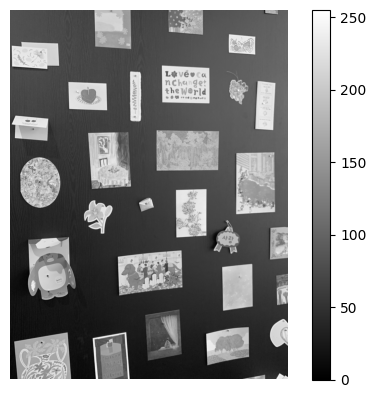

In [88]:
I = Image.open('/content/IMG_1133.jpeg').convert('L')
f = np.array(I)
plt.imshow(f,cmap='gray')
plt.axis('off')
plt.colorbar()
plt.show()

## 2. 적절한 전처리를 통해 영상의 noise를 줄이기

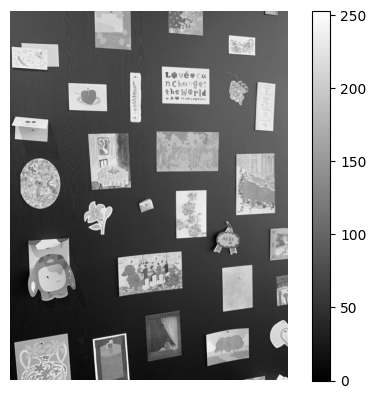

In [89]:
f_denoised = signal.medfilt2d(f,7)
plt.imshow(f_denoised,cmap='gray')
plt.axis('off')
plt.colorbar()
plt.show()

## 3. 적절한 임계값을 찾아 thresholding을 통해 binary mask를 생성하기

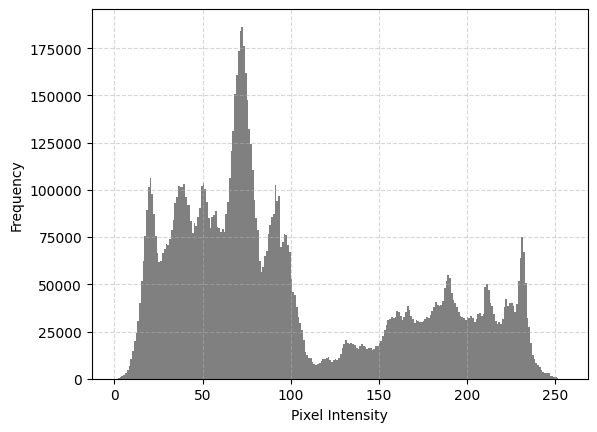

In [90]:
plt.hist(f_denoised.ravel(), bins=256, range=(0,256), color='gray')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

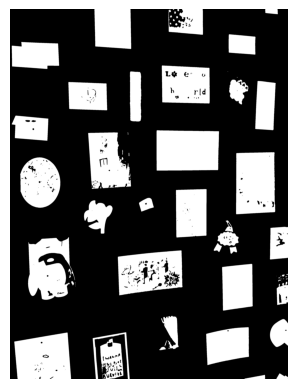

In [91]:
th_val = 128
f_mask = f_denoised > th_val
plt.imshow(f_mask,cmap='gray')
plt.axis('off')
plt.show()

## 4. Connected component 추출을 통해 object를 분리하고, 각각의 pixel수를 계산하기

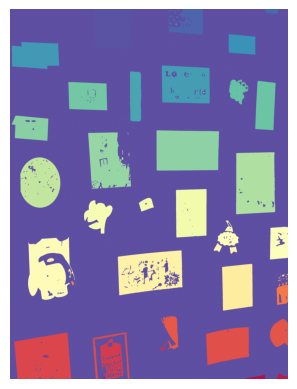

In [92]:
labels, nums = nd.label(f_mask)
plt.imshow(labels,cmap='Spectral_r')
plt.axis('off')
plt.show()

In [93]:
cc = np.zeros((nums-1,2))
for i in range(1,nums):
  cc[i-1,0] = i
  cc[i-1,1] = np.sum(labels==i)
  print(f'index: {int(cc[i-1,0])}, number of pixels: {int(cc[i-1,1])}')

index: 1, number of pixels: 165183
index: 2, number of pixels: 108
index: 3, number of pixels: 397
index: 4, number of pixels: 70736
index: 5, number of pixels: 6838
index: 6, number of pixels: 351
index: 7, number of pixels: 354
index: 8, number of pixels: 381
index: 9, number of pixels: 328
index: 10, number of pixels: 251
index: 11, number of pixels: 438
index: 12, number of pixels: 57412
index: 13, number of pixels: 131627
index: 14, number of pixels: 193949
index: 15, number of pixels: 63636
index: 16, number of pixels: 9
index: 17, number of pixels: 6
index: 18, number of pixels: 145
index: 19, number of pixels: 30
index: 20, number of pixels: 34634
index: 21, number of pixels: 103590
index: 22, number of pixels: 120137
index: 23, number of pixels: 211
index: 24, number of pixels: 99
index: 25, number of pixels: 86970
index: 26, number of pixels: 290525
index: 27, number of pixels: 207739
index: 28, number of pixels: 109
index: 29, number of pixels: 2
index: 30, number of pixels:

## 5. 추출한 connected component 중 가장 큰 것과 작은 것을 시각화하기

In [98]:
min_size = 1000
valid = cc[cc[:,1] >= min_size]

ind_max = np.argmax(valid[:,1])
print(f'the largest component: label {int(valid[ind_max,0])}, # of pixels: {int(valid[ind_max,1])}')
ind_min = np.argmin(valid[:,1])
print(f'the smallest component: label {int(valid[ind_min,0])}, # of pixels: {int(valid[ind_min,1])}')

the largest component: label 26, # of pixels: 290525
the smallest component: label 92, # of pixels: 1611


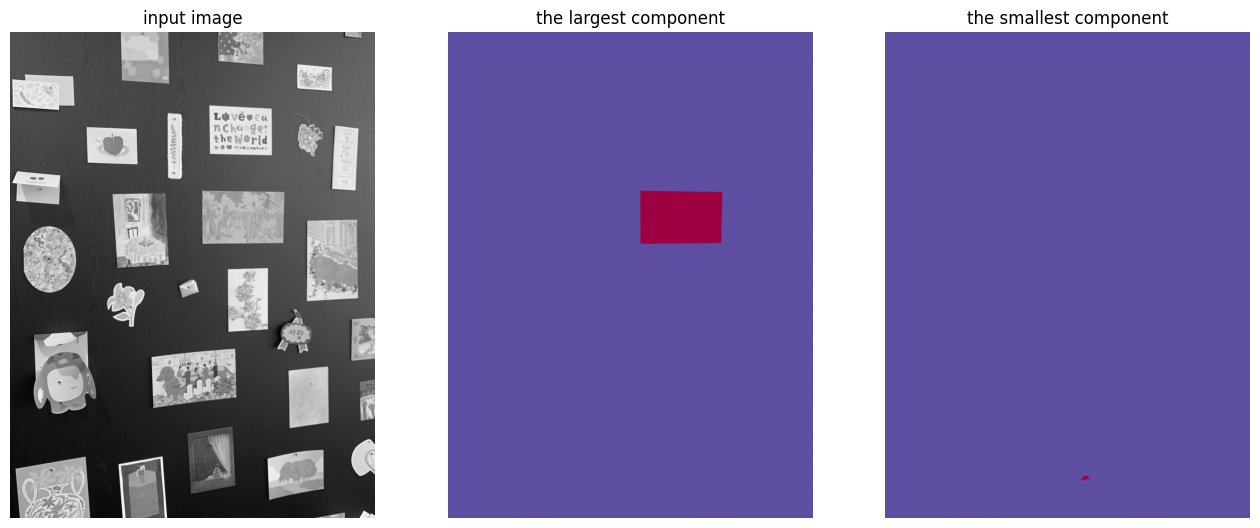

In [99]:
plt.figure(figsize=(16,9))
plt.subplot(131)
plt.imshow(f,cmap='gray')
plt.axis('off')
plt.title('input image')
plt.subplot(132)
plt.imshow(labels==valid[ind_max,0],cmap='Spectral_r')
plt.axis('off')
plt.title('the largest component')
plt.subplot(133)
plt.imshow(labels==valid[ind_min,0],cmap='Spectral_r')
plt.axis('off')
plt.title('the smallest component')
plt.show()